# LLM Few-Shot Annotation Analysis

This notebook compares Llama-3-8B-Instruct **Few-Shot** annotations with human annotations for conspiracy theory detection.

## Structure:
1. **Setup & Data Loading** - Load LLM and human annotations
2. **Data Overview** - Basic statistics and data quality checks
3. **Classification Comparison** - Compare `is_conspiratorial` and `supports_conspiracy` labels
4. **Span Comparison** - Compare span annotations for each label
5. **Metrics & Evaluation** - Calculate accuracy, precision, recall, F1 scores
6. **Disagreement Analysis** - Examine cases where LLM and human disagree
7. **Visualizations** - Create plots and charts for insights
8. **Summary** - Key findings and conclusions

Let's proceed step by step!


In [1]:
# Step 1: Setup & Imports

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import json
from sklearn.metrics import confusion_matrix, classification_report, precision_recall_fscore_support
from collections import Counter
import warnings
warnings.filterwarnings('ignore')

# Set paths
PROJECT_ROOT = Path("/home/ashrafs/projects/Conspiracy-Proj").resolve()
DATA_DIR = PROJECT_ROOT / "Data"
OUTPUT_DIR = PROJECT_ROOT / "outputs"
NOTEBOOK_DIR = PROJECT_ROOT / "Notebooks"

# Set plotting style
sns.set_theme(context="notebook", style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 11
%matplotlib inline

print("✓ Setup complete!")
print(f"Project root: {PROJECT_ROOT}")
print(f"Data directory: {DATA_DIR}")
print(f"Output directory: {OUTPUT_DIR}")


✓ Setup complete!
Project root: /home/ashrafs/projects/Conspiracy-Proj
Data directory: /home/ashrafs/projects/Conspiracy-Proj/Data
Output directory: /home/ashrafs/projects/Conspiracy-Proj/outputs


In [2]:
# Step 2: Load Data

# Load LLM annotations (Few-Shot)
llm_class = pd.read_csv(OUTPUT_DIR / "llama8b-fewshot_all_classifications.csv")
llm_spans = pd.read_csv(OUTPUT_DIR / "llama8b-fewshot_all_span_annotations.csv")

print("LLM Annotations:")
print(f"  Classifications: {len(llm_class)} rows")
print(f"  Span annotations: {len(llm_spans)} rows")
print(f"  Unique text_ids: {llm_class['text_id'].nunique()}")

# Load human annotations
human_class = pd.read_csv(DATA_DIR / "all_classifications.csv")
human_spans = pd.read_csv(DATA_DIR / "all_span_annotations.csv")

print("\nHuman Annotations:")
print(f"  Classifications: {len(human_class)} rows")
print(f"  Span annotations: {len(human_spans)} rows")
print(f"  Unique text_ids: {human_class['text_id'].nunique()}")

# For comparison: deduplicate human annotations (one per text_id, like LLM)
human_class_unique = human_class.drop_duplicates(subset="text_id", keep="first")
human_spans_unique = human_spans.drop_duplicates(subset="text_id", keep="first")

print(f"\nHuman (deduplicated for comparison):")
print(f"  Classifications: {len(human_class_unique)} rows")
print(f"  Span annotations: {len(human_spans_unique)} rows")

print("\n✓ Data loaded successfully!")


LLM Annotations:
  Classifications: 2077 rows
  Span annotations: 2077 rows
  Unique text_ids: 2077

Human Annotations:
  Classifications: 3243 rows
  Span annotations: 934 rows
  Unique text_ids: 2077

Human (deduplicated for comparison):
  Classifications: 2077 rows
  Span annotations: 755 rows

✓ Data loaded successfully!


## Step 3: Data Overview

Let's examine the basic structure and statistics of both annotation sets.


In [3]:
# Examine LLM classification columns
print("LLM Classification Columns:")
print(llm_class.columns.tolist())
print("\nFirst few rows:")
print(llm_class.head(3))


LLM Classification Columns:
['annotator_id', 'text_id', 'annotation_id', 'text', 'conspiracy', 'supportive', 'misinformative', 'confidence', 'rationale_short']

First few rows:
  annotator_id  text_id annotation_id  \
0          llm    21580         llm_1   
1          llm    21581         llm_2   
2          llm    21634         llm_3   

                                                text conspiracy supportive  \
0  Someone should comment this under Elon Musks C...        yes         no   
1  WLM viewing #4\n\nThe rule of Nature\nMandator...         no         no   
2  Imagine being a Normie waking up everyday not ...         no         no   

   misinformative  confidence                       rationale_short  
0             NaN         0.8     plan_event + out_group + in_group  
1             NaN         1.0  No identifiable plan/event or secret  
2             NaN         1.0  No identifiable plan/event or secret  


In [4]:
# Examine human classification columns
print("Human Classification Columns:")
print(human_class_unique.columns.tolist())
print("\nFirst few rows:")
print(human_class_unique[['text_id', 'conspiracy', 'supportive']].head(3))


Human Classification Columns:
['annotator_id', 'text_id', 'annotation_id', 'text', 'conspiracy', 'supportive', 'misinformative']

First few rows:
   text_id conspiracy supportive
0    21580         no        yes
1    21581         no         no
2    21634         no         no


In [6]:
# Check data quality: missing values, value counts
print("LLM Classification Value Counts:")
print(f"  conspiracy: {llm_class['conspiracy'].value_counts().to_dict()}")
print(f"  supportive: {llm_class['supportive'].value_counts().to_dict()}")

print("\nHuman Classification Value Counts (deduplicated):")
print(f"  conspiracy: {human_class_unique['conspiracy'].value_counts().to_dict()}")
print(f"  supportive: {human_class_unique['supportive'].value_counts().to_dict()}")

# Check for missing values
print("\nMissing values:")
print(f"  LLM: {llm_class[['conspiracy', 'supportive']].isnull().sum().to_dict()}")
print(f"  Human: {human_class_unique[['conspiracy', 'supportive']].isnull().sum().to_dict()}")


LLM Classification Value Counts:
  conspiracy: {'no': 1313, 'yes': 764}
  supportive: {'no': 1911, 'yes': 166}

Human Classification Value Counts (deduplicated):
  conspiracy: {'no': 1633, 'yes': 406}
  supportive: {'no': 1142, 'yes': 899}

Missing values:
  LLM: {'conspiracy': 0, 'supportive': 0}
  Human: {'conspiracy': 38, 'supportive': 36}


## Step 4: Merge Data for Comparison

Merge LLM and human annotations on `text_id` to enable direct comparison.


In [7]:
# Merge classifications on text_id
merged_class = human_class_unique.merge(
    llm_class[['text_id', 'conspiracy', 'supportive', 'confidence', 'rationale_short']],
    on='text_id',
    suffixes=('_human', '_llm'),
    how='inner'
)

print(f"Merged classifications: {len(merged_class)} rows")
print(f"Matched text_ids: {merged_class['text_id'].nunique()}")

# Merge spans on text_id
merged_spans = human_spans_unique.merge(
    llm_spans,
    on='text_id',
    suffixes=('_human', '_llm'),
    how='inner'
)

print(f"Merged spans: {len(merged_spans)} rows")
print(f"Matched text_ids: {merged_spans['text_id'].nunique()}")

print("\n✓ Data merged successfully!")


Merged classifications: 2077 rows
Matched text_ids: 2077
Merged spans: 749 rows
Matched text_ids: 749

✓ Data merged successfully!


## Step 5: Classification Comparison

Compare LLM and human labels for `conspiracy` and `supportive`.


In [9]:
# Convert yes/no to boolean for easier comparison
def yn_to_bool(val):
    if pd.isna(val):
        return False  # Default to False for missing values
    val_str = str(val).lower().strip()
    return val_str == 'yes' or val_str == 'true'

# Create comparison columns - explicitly convert to boolean
merged_class['conspiracy_human_bool'] = merged_class['conspiracy_human'].apply(yn_to_bool).astype(bool)
merged_class['conspiracy_llm_bool'] = merged_class['conspiracy_llm'].apply(yn_to_bool).astype(bool)
merged_class['supportive_human_bool'] = merged_class['supportive_human'].apply(yn_to_bool).astype(bool)
merged_class['supportive_llm_bool'] = merged_class['supportive_llm'].apply(yn_to_bool).astype(bool)

# Agreement columns (handle NaN cases)
merged_class['conspiracy_agree'] = (merged_class['conspiracy_human_bool'] == merged_class['conspiracy_llm_bool']).fillna(False)
merged_class['supportive_agree'] = (merged_class['supportive_human_bool'] == merged_class['supportive_llm_bool']).fillna(False)

print("Agreement Statistics:")
print(f"  conspiracy: {merged_class['conspiracy_agree'].sum()} / {len(merged_class)} = {merged_class['conspiracy_agree'].mean():.1%}")
print(f"  supportive: {merged_class['supportive_agree'].sum()} / {len(merged_class)} = {merged_class['supportive_agree'].mean():.1%}")

# Verify data types
print(f"\nData types:")
print(f"  conspiracy_human_bool: {merged_class['conspiracy_human_bool'].dtype}")
print(f"  conspiracy_llm_bool: {merged_class['conspiracy_llm_bool'].dtype}")
print(f"  Null values in bool cols: conspiracy_human={merged_class['conspiracy_human_bool'].isna().sum()}, conspiracy_llm={merged_class['conspiracy_llm_bool'].isna().sum()}")


Agreement Statistics:
  conspiracy: 1491 / 2077 = 71.8%
  supportive: 1208 / 2077 = 58.2%

Data types:
  conspiracy_human_bool: bool
  conspiracy_llm_bool: bool
  Null values in bool cols: conspiracy_human=0, conspiracy_llm=0


In [10]:
# Confusion matrices
print("=" * 70)
print("CONSPIRACY LABEL COMPARISON")
print("=" * 70)

# Filter out None values and ensure boolean types
consp_mask = merged_class['conspiracy_human_bool'].notna() & merged_class['conspiracy_llm_bool'].notna()
consp_data = merged_class[consp_mask].copy()

# Ensure boolean types (convert None to False if any remain, though shouldn't after filter)
consp_data['conspiracy_human_bool'] = consp_data['conspiracy_human_bool'].astype(bool)
consp_data['conspiracy_llm_bool'] = consp_data['conspiracy_llm_bool'].astype(bool)

cm_consp = confusion_matrix(consp_data['conspiracy_human_bool'], consp_data['conspiracy_llm_bool'], labels=[True, False])
print("\nConfusion Matrix (Human vs LLM):")
print("              LLM: Yes    No")
print(f"Human: Yes     {cm_consp[0,0]:5d}  {cm_consp[0,1]:5d}")
print(f"Human: No      {cm_consp[1,0]:5d}  {cm_consp[1,1]:5d}")

# Calculate metrics
tp, fn = cm_consp[0,0], cm_consp[0,1]  # True positives, False negatives
fp, tn = cm_consp[1,0], cm_consp[1,1]  # False positives, True negatives

accuracy = (tp + tn) / (tp + tn + fp + fn) if (tp + tn + fp + fn) > 0 else 0
precision = tp / (tp + fp) if (tp + fp) > 0 else 0
recall = tp / (tp + fn) if (tp + fn) > 0 else 0
f1 = 2 * (precision * recall) / (precision + recall) if (precision + recall) > 0 else 0

print(f"\nMetrics:")
print(f"  Accuracy:  {accuracy:.3f} ({accuracy*100:.1f}%)")
print(f"  Precision: {precision:.3f}")
print(f"  Recall:    {recall:.3f}")
print(f"  F1 Score:  {f1:.3f}")
print(f"\n  TP={tp}, TN={tn}, FP={fp}, FN={fn}")


CONSPIRACY LABEL COMPARISON

Confusion Matrix (Human vs LLM):
              LLM: Yes    No
Human: Yes       292    114
Human: No        472   1199

Metrics:
  Accuracy:  0.718 (71.8%)
  Precision: 0.382
  Recall:    0.719
  F1 Score:  0.499

  TP=292, TN=1199, FP=472, FN=114


In [11]:
print("=" * 70)
print("SUPPORTIVE LABEL COMPARISON")
print("=" * 70)

# Filter out None values and ensure boolean types
supp_mask = merged_class['supportive_human_bool'].notna() & merged_class['supportive_llm_bool'].notna()
supp_data = merged_class[supp_mask].copy()

# Ensure boolean types
supp_data['supportive_human_bool'] = supp_data['supportive_human_bool'].astype(bool)
supp_data['supportive_llm_bool'] = supp_data['supportive_llm_bool'].astype(bool)

cm_supp = confusion_matrix(supp_data['supportive_human_bool'], supp_data['supportive_llm_bool'], labels=[True, False])
print("\nConfusion Matrix (Human vs LLM):")
print("              LLM: Yes    No")
print(f"Human: Yes     {cm_supp[0,0]:5d}  {cm_supp[0,1]:5d}")
print(f"Human: No      {cm_supp[1,0]:5d}  {cm_supp[1,1]:5d}")

# Calculate metrics
tp, fn = cm_supp[0,0], cm_supp[0,1]
fp, tn = cm_supp[1,0], cm_supp[1,1]

accuracy_supp = (tp + tn) / (tp + tn + fp + fn) if (tp + tn + fp + fn) > 0 else 0
precision_supp = tp / (tp + fp) if (tp + fp) > 0 else 0
recall_supp = tp / (tp + fn) if (tp + fn) > 0 else 0
f1_supp = 2 * (precision_supp * recall_supp) / (precision_supp + recall_supp) if (precision_supp + recall_supp) > 0 else 0

print(f"\nMetrics:")
print(f"  Accuracy:  {accuracy_supp:.3f} ({accuracy_supp*100:.1f}%)")
print(f"  Precision: {precision_supp:.3f}")
print(f"  Recall:    {recall_supp:.3f}")
print(f"  F1 Score:  {f1_supp:.3f}")
print(f"\n  TP={tp}, TN={tn}, FP={fp}, FN={fn}")


SUPPORTIVE LABEL COMPARISON

Confusion Matrix (Human vs LLM):
              LLM: Yes    No
Human: Yes        98    801
Human: No         68   1110

Metrics:
  Accuracy:  0.582 (58.2%)
  Precision: 0.590
  Recall:    0.109
  F1 Score:  0.184

  TP=98, TN=1110, FP=68, FN=801


## Step 6: Visualizations

Create plots to visualize the comparison results.


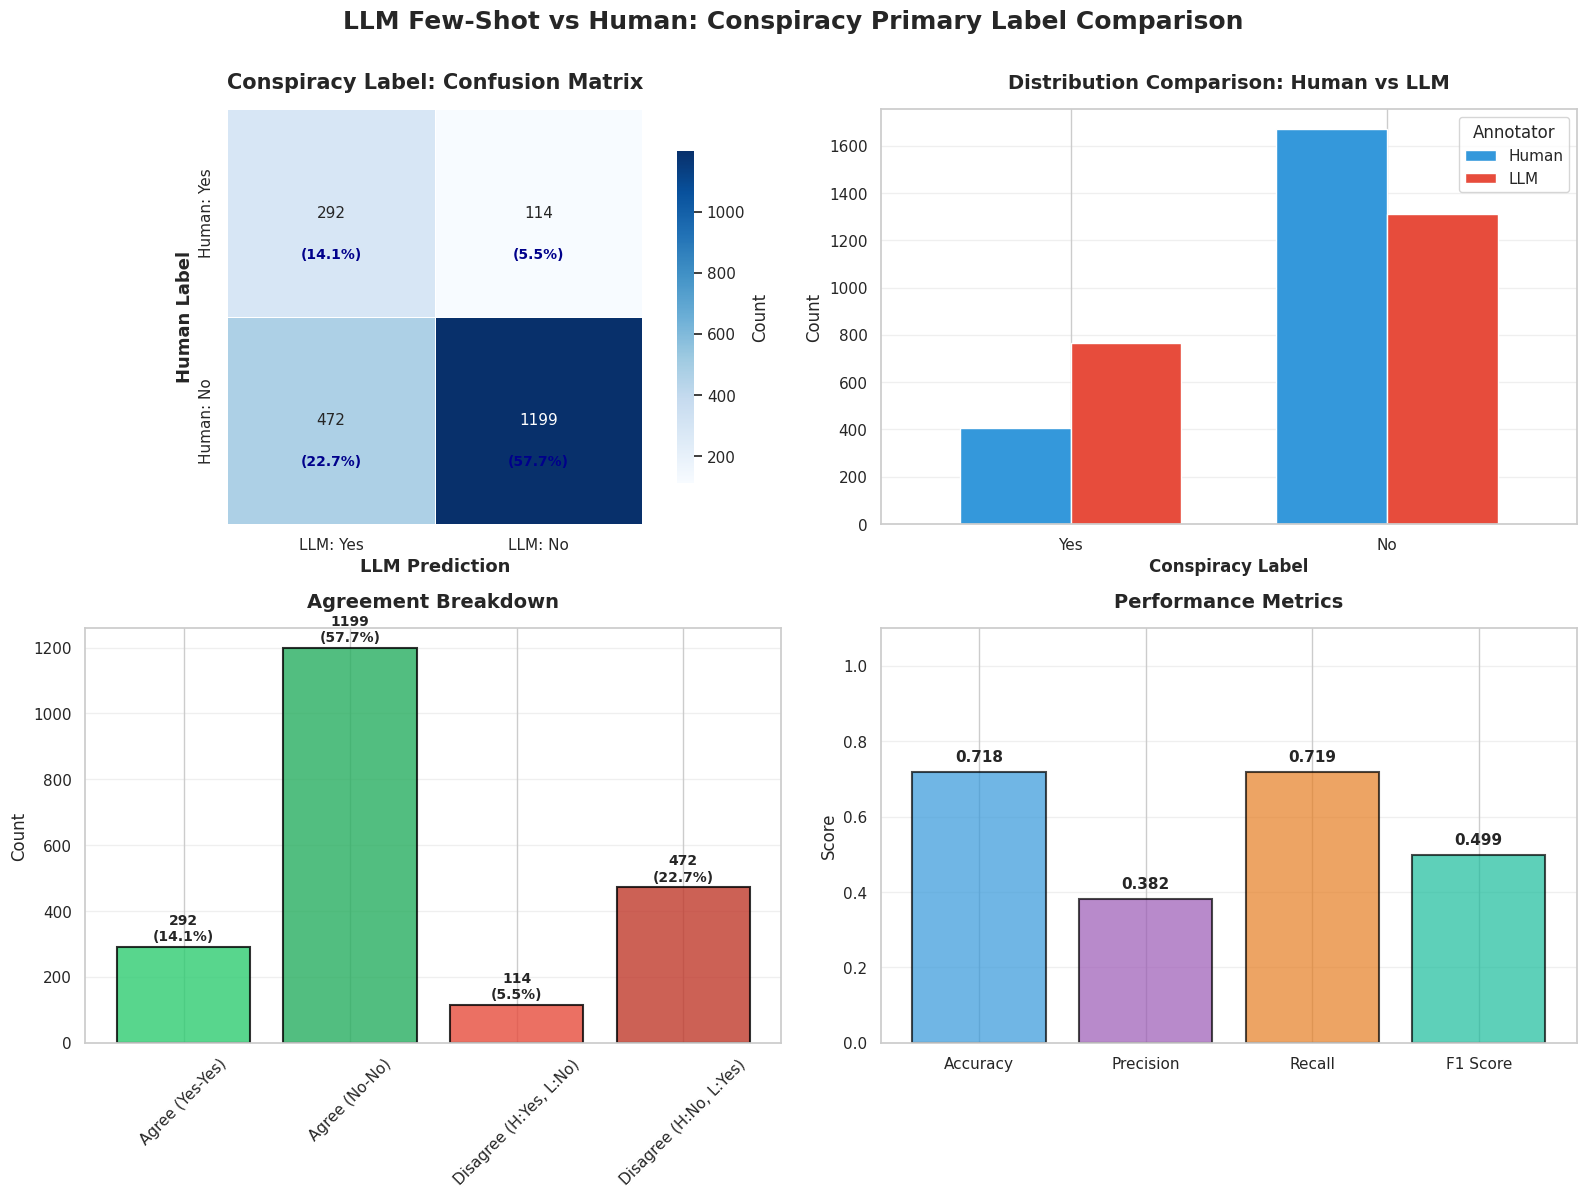

✓ Conspiracy label comparison saved to plots/llm_fewshot_conspiracy_label_comparison.png


In [ ]:
# ============================================================
# VISUALIZATION 1: CONSPIRACY PRIMARY LABEL COMPARISON
# ============================================================

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. Confusion Matrix Heatmap
sns.heatmap(cm_consp, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['LLM: Yes', 'LLM: No'], 
            yticklabels=['Human: Yes', 'Human: No'],
            cbar_kws={'label': 'Count', 'shrink': 0.8}, ax=axes[0,0], 
            square=True, linewidths=0.5)
axes[0,0].set_xlabel('LLM Prediction', fontsize=13, fontweight='bold')
axes[0,0].set_ylabel('Human Label', fontsize=13, fontweight='bold')
axes[0,0].set_title('Conspiracy Label: Confusion Matrix', fontsize=15, fontweight='bold', pad=15)
# Add percentages
total = cm_consp.sum()
for i in range(2):
    for j in range(2):
        pct = (cm_consp[i,j] / total) * 100
        axes[0,0].text(j+0.5, i+0.7, f'({pct:.1f}%)', 
                      ha='center', va='center', fontsize=10, color='darkblue', fontweight='bold')

# 2. Distribution Comparison (Stacked Bar)
label_counts = pd.DataFrame({
    'Human': [
        (merged_class['conspiracy_human_bool'] == True).sum(),
        (merged_class['conspiracy_human_bool'] == False).sum()
    ],
    'LLM': [
        (merged_class['conspiracy_llm_bool'] == True).sum(),
        (merged_class['conspiracy_llm_bool'] == False).sum()
    ]
}, index=['Yes', 'No'])

label_counts.plot(kind='bar', ax=axes[0,1], color=['#3498db', '#e74c3c'], width=0.7)
axes[0,1].set_xlabel('Conspiracy Label', fontsize=12, fontweight='bold')
axes[0,1].set_ylabel('Count', fontsize=12)
axes[0,1].set_title('Distribution Comparison: Human vs LLM', fontsize=14, fontweight='bold', pad=15)
axes[0,1].legend(title='Annotator', fontsize=11, title_fontsize=12)
axes[0,1].grid(axis='y', alpha=0.3)
axes[0,1].set_xticklabels(['Yes', 'No'], rotation=0)

# 3. Agreement/Disagreement Breakdown
agree_counts = pd.Series({
    'Agree (Yes-Yes)': ((merged_class['conspiracy_human_bool'] == True) & 
                        (merged_class['conspiracy_llm_bool'] == True)).sum(),
    'Agree (No-No)': ((merged_class['conspiracy_human_bool'] == False) & 
                      (merged_class['conspiracy_llm_bool'] == False)).sum(),
    'Disagree (H:Yes, L:No)': ((merged_class['conspiracy_human_bool'] == True) & 
                                (merged_class['conspiracy_llm_bool'] == False)).sum(),
    'Disagree (H:No, L:Yes)': ((merged_class['conspiracy_human_bool'] == False) & 
                                (merged_class['conspiracy_llm_bool'] == True)).sum()
})

colors_agree = ['#2ecc71', '#27ae60', '#e74c3c', '#c0392b']
bars = axes[1,0].bar(agree_counts.index, agree_counts.values, color=colors_agree, alpha=0.8, edgecolor='black', linewidth=1.5)
axes[1,0].set_ylabel('Count', fontsize=12)
axes[1,0].set_title('Agreement Breakdown', fontsize=14, fontweight='bold', pad=15)
axes[1,0].tick_params(axis='x', rotation=45)
axes[1,0].grid(axis='y', alpha=0.3)

# Add value labels
for bar, value in zip(bars, agree_counts.values):
    height = bar.get_height()
    axes[1,0].text(bar.get_x() + bar.get_width()/2., height + 10,
                   f'{value}\n({value/len(merged_class)*100:.1f}%)',
                   ha='center', va='bottom', fontsize=10, fontweight='bold')

# 4. Metrics Summary
metrics_data = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1 Score'],
    'Value': [accuracy, precision, recall, f1]
})

bars = axes[1,1].bar(metrics_data['Metric'], metrics_data['Value'], 
                     color=['#3498db', '#9b59b6', '#e67e22', '#1abc9c'], 
                     alpha=0.7, edgecolor='black', linewidth=1.5)
axes[1,1].set_ylabel('Score', fontsize=12)
axes[1,1].set_title('Performance Metrics', fontsize=14, fontweight='bold', pad=15)
axes[1,1].set_ylim(0, 1.1)
axes[1,1].grid(axis='y', alpha=0.3)

# Add value labels
for bar, value in zip(bars, metrics_data['Value']):
    height = bar.get_height()
    axes[1,1].text(bar.get_x() + bar.get_width()/2., height + 0.02,
                   f'{value:.3f}', ha='center', va='bottom', fontsize=11, fontweight='bold')

plt.suptitle('LLM Few-Shot vs Human: Conspiracy Primary Label Comparison', 
             fontsize=18, fontweight='bold', y=0.995)
plt.tight_layout(rect=[0, 0, 1, 0.99])
plt.savefig(PROJECT_ROOT / 'plots' / 'llm_fewshot_conspiracy_label_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ Conspiracy label comparison saved to plots/llm_fewshot_conspiracy_label_comparison.png")


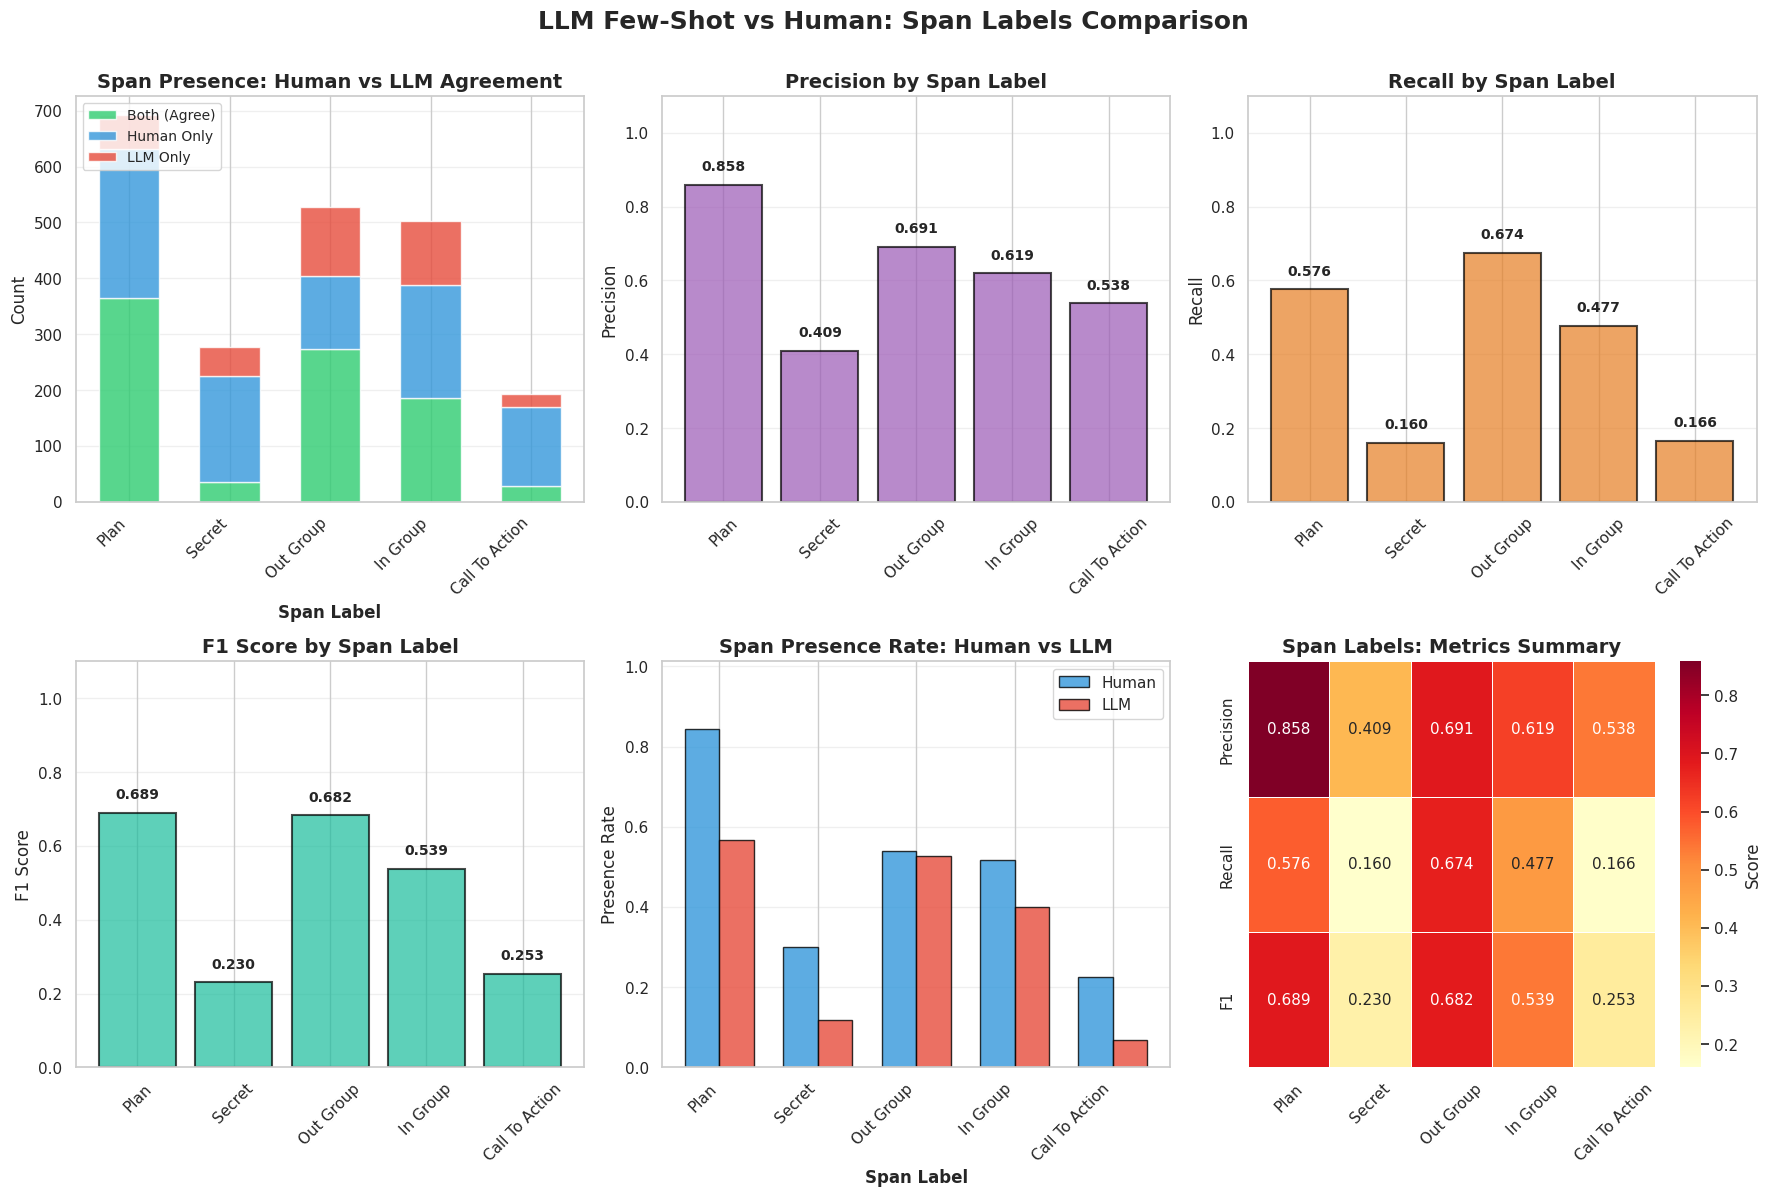

✓ Span labels comparison saved to plots/llm_fewshot_span_labels_comparison.png

SPAN LABELS SUMMARY TABLE
         Label  Both  Human Only  LLM Only  Neither  Precision   Recall       F1
          Plan   364         268        60       57   0.858491 0.575949 0.689394
        Secret    36         189        52      472   0.409091 0.160000 0.230032
     Out Group   273         132       122      222   0.691139 0.674074 0.682500
      In Group   185         203       114      247   0.618729 0.476804 0.538574
Call To Action    28         141        24      556   0.538462 0.165680 0.253394


In [ ]:
# ============================================================
# VISUALIZATION 2: SPAN LABELS COMPARISON
# ============================================================

# Prepare span comparison data
span_labels = ['plan', 'secret', 'out-group', 'in-group', 'call-to-action']
span_comparison_data = []

for label in span_labels:
    human_col = label + '_human'
    llm_col = label + '_llm'
    
    if human_col in merged_spans.columns and llm_col in merged_spans.columns:
        human_has = merged_spans[human_col].notna() & (merged_spans[human_col].astype(str).str.strip() != '')
        llm_has = merged_spans[llm_col].notna() & (merged_spans[llm_col].astype(str).str.strip() != '')
        
        both = (human_has & llm_has).sum()
        human_only = (human_has & ~llm_has).sum()
        llm_only = (~human_has & llm_has).sum()
        neither = (~human_has & ~llm_has).sum()
        
        total = len(merged_spans)
        
        if (both + human_only + llm_only) > 0:
            precision = both / (both + llm_only) if (both + llm_only) > 0 else 0
            recall = both / (both + human_only) if (both + human_only) > 0 else 0
            f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0
        else:
            precision = recall = f1 = 0
        
        span_comparison_data.append({
            'Label': label.replace('-', ' ').title(),
            'Both': both,
            'Human Only': human_only,
            'LLM Only': llm_only,
            'Neither': neither,
            'Precision': precision,
            'Recall': recall,
            'F1': f1
        })

span_df = pd.DataFrame(span_comparison_data)

# Create comprehensive span comparison visualization
fig, axes = plt.subplots(2, 3, figsize=(18, 12))
axes = axes.flatten()

# 1. Stacked bar chart showing agreement/disagreement per label
labels = span_df['Label'].values
x = np.arange(len(labels))
width = 0.6

axes[0].bar(x, span_df['Both'], width, label='Both (Agree)', color='#2ecc71', alpha=0.8)
axes[0].bar(x, span_df['Human Only'], width, bottom=span_df['Both'], 
            label='Human Only', color='#3498db', alpha=0.8)
axes[0].bar(x, span_df['LLM Only'], width, 
            bottom=span_df['Both'] + span_df['Human Only'], 
            label='LLM Only', color='#e74c3c', alpha=0.8)

axes[0].set_xlabel('Span Label', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Count', fontsize=12)
axes[0].set_title('Span Presence: Human vs LLM Agreement', fontsize=14, fontweight='bold')
axes[0].set_xticks(x)
axes[0].set_xticklabels(labels, rotation=45, ha='right')
axes[0].legend(loc='upper left', fontsize=10)
axes[0].grid(axis='y', alpha=0.3)

# 2. Precision per label
axes[1].bar(span_df['Label'], span_df['Precision'], color='#9b59b6', alpha=0.7, edgecolor='black', linewidth=1.5)
axes[1].set_ylabel('Precision', fontsize=12)
axes[1].set_title('Precision by Span Label', fontsize=14, fontweight='bold')
axes[1].set_ylim(0, 1.1)
axes[1].tick_params(axis='x', rotation=45)
axes[1].grid(axis='y', alpha=0.3)
for i, (label, prec) in enumerate(zip(span_df['Label'], span_df['Precision'])):
    axes[1].text(i, prec + 0.03, f'{prec:.3f}', ha='center', va='bottom', fontsize=10, fontweight='bold')

# 3. Recall per label
axes[2].bar(span_df['Label'], span_df['Recall'], color='#e67e22', alpha=0.7, edgecolor='black', linewidth=1.5)
axes[2].set_ylabel('Recall', fontsize=12)
axes[2].set_title('Recall by Span Label', fontsize=14, fontweight='bold')
axes[2].set_ylim(0, 1.1)
axes[2].tick_params(axis='x', rotation=45)
axes[2].grid(axis='y', alpha=0.3)
for i, (label, rec) in enumerate(zip(span_df['Label'], span_df['Recall'])):
    axes[2].text(i, rec + 0.03, f'{rec:.3f}', ha='center', va='bottom', fontsize=10, fontweight='bold')

# 4. F1 Score per label
axes[3].bar(span_df['Label'], span_df['F1'], color='#1abc9c', alpha=0.7, edgecolor='black', linewidth=1.5)
axes[3].set_ylabel('F1 Score', fontsize=12)
axes[3].set_title('F1 Score by Span Label', fontsize=14, fontweight='bold')
axes[3].set_ylim(0, 1.1)
axes[3].tick_params(axis='x', rotation=45)
axes[3].grid(axis='y', alpha=0.3)
for i, (label, f1_val) in enumerate(zip(span_df['Label'], span_df['F1'])):
    axes[3].text(i, f1_val + 0.03, f'{f1_val:.3f}', ha='center', va='bottom', fontsize=10, fontweight='bold')

# 5. Comparison: Human vs LLM presence rates
human_presence = []
llm_presence = []
for label in span_labels:
    human_col = label + '_human'
    llm_col = label + '_llm'
    if human_col in merged_spans.columns and llm_col in merged_spans.columns:
        human_has = (merged_spans[human_col].notna() & 
                    (merged_spans[human_col].astype(str).str.strip() != '')).sum()
        llm_has = (merged_spans[llm_col].notna() & 
                  (merged_spans[llm_col].astype(str).str.strip() != '')).sum()
        human_presence.append(human_has / len(merged_spans))
        llm_presence.append(llm_has / len(merged_spans))

x = np.arange(len(labels))
width = 0.35
axes[4].bar(x - width/2, human_presence, width, label='Human', color='#3498db', alpha=0.8, edgecolor='black')
axes[4].bar(x + width/2, llm_presence, width, label='LLM', color='#e74c3c', alpha=0.8, edgecolor='black')
axes[4].set_xlabel('Span Label', fontsize=12, fontweight='bold')
axes[4].set_ylabel('Presence Rate', fontsize=12)
axes[4].set_title('Span Presence Rate: Human vs LLM', fontsize=14, fontweight='bold')
axes[4].set_xticks(x)
axes[4].set_xticklabels(labels, rotation=45, ha='right')
axes[4].legend(fontsize=11)
axes[4].grid(axis='y', alpha=0.3)
axes[4].set_ylim(0, max(max(human_presence), max(llm_presence)) * 1.2)

# 6. Overall metrics summary (heatmap)
metrics_heatmap = span_df[['Label', 'Precision', 'Recall', 'F1']].set_index('Label')
sns.heatmap(metrics_heatmap.T, annot=True, fmt='.3f', cmap='YlOrRd', 
            cbar_kws={'label': 'Score'}, ax=axes[5], square=False, linewidths=0.5)
axes[5].set_title('Span Labels: Metrics Summary', fontsize=14, fontweight='bold')
axes[5].set_xlabel('')
axes[5].tick_params(axis='x', rotation=45)

plt.suptitle('LLM Few-Shot vs Human: Span Labels Comparison', 
             fontsize=18, fontweight='bold', y=0.995)
plt.tight_layout(rect=[0, 0, 1, 0.99])
plt.savefig(PROJECT_ROOT / 'plots' / 'llm_fewshot_span_labels_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ Span labels comparison saved to plots/llm_fewshot_span_labels_comparison.png")

# Print summary table
print("\n" + "="*70)
print("SPAN LABELS SUMMARY TABLE")
print("="*70)
print(span_df.to_string(index=False))


### Additional Visualization: Supportive Label (Optional)


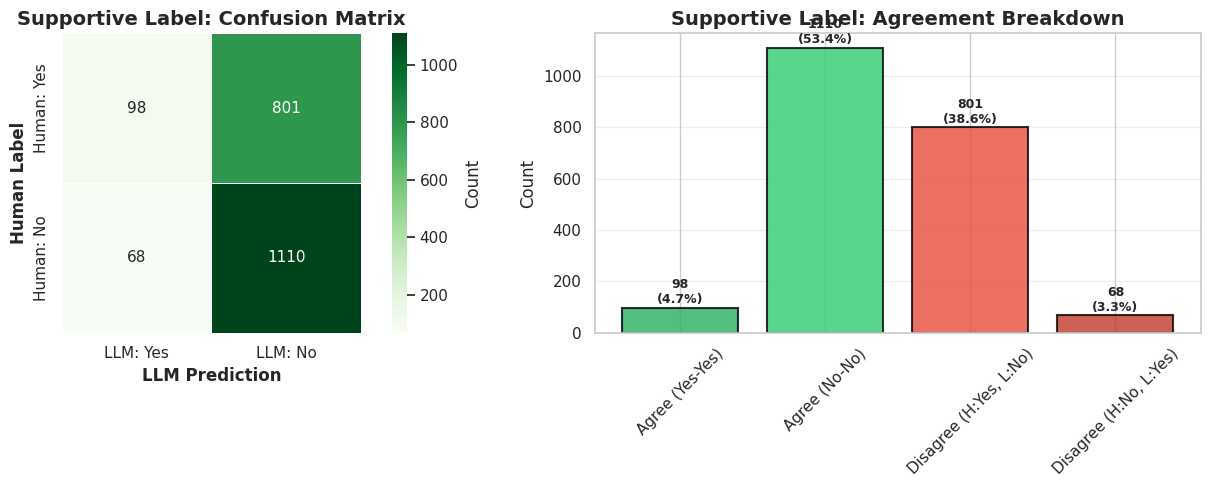

✓ Supportive label comparison saved to plots/llm_fewshot_supportive_label_comparison.png


In [ ]:
# Optional: Supportive label visualization (similar to conspiracy)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Supportive confusion matrix
sns.heatmap(cm_supp, annot=True, fmt='d', cmap='Greens',
            xticklabels=['LLM: Yes', 'LLM: No'], 
            yticklabels=['Human: Yes', 'Human: No'],
            cbar_kws={'label': 'Count'}, ax=axes[0], 
            square=True, linewidths=0.5)
axes[0].set_xlabel('LLM Prediction', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Human Label', fontsize=12, fontweight='bold')
axes[0].set_title('Supportive Label: Confusion Matrix', fontsize=14, fontweight='bold')

# Supportive agreement breakdown
supp_agree_counts = pd.Series({
    'Agree (Yes-Yes)': ((supp_data['supportive_human_bool'] == True) & 
                        (supp_data['supportive_llm_bool'] == True)).sum(),
    'Agree (No-No)': ((supp_data['supportive_human_bool'] == False) & 
                      (supp_data['supportive_llm_bool'] == False)).sum(),
    'Disagree (H:Yes, L:No)': ((supp_data['supportive_human_bool'] == True) & 
                                (supp_data['supportive_llm_bool'] == False)).sum(),
    'Disagree (H:No, L:Yes)': ((supp_data['supportive_human_bool'] == False) & 
                                (supp_data['supportive_llm_bool'] == True)).sum()
})

colors = ['#27ae60', '#2ecc71', '#e74c3c', '#c0392b']
bars = axes[1].bar(supp_agree_counts.index, supp_agree_counts.values, 
                   color=colors, alpha=0.8, edgecolor='black', linewidth=1.5)
axes[1].set_ylabel('Count', fontsize=12)
axes[1].set_title('Supportive Label: Agreement Breakdown', fontsize=14, fontweight='bold')
axes[1].tick_params(axis='x', rotation=45)
axes[1].grid(axis='y', alpha=0.3)

for bar, value in zip(bars, supp_agree_counts.values):
    height = bar.get_height()
    axes[1].text(bar.get_x() + bar.get_width()/2., height + 5,
                 f'{value}\n({value/len(supp_data)*100:.1f}%)',
                 ha='center', va='bottom', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.savefig(PROJECT_ROOT / 'plots' / 'llm_fewshot_supportive_label_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ Supportive label comparison saved to plots/llm_fewshot_supportive_label_comparison.png")


## Step 7: Span Comparison

Compare span annotations between LLM and human annotators.


In [15]:
# Span label columns
span_labels = ['plan', 'secret', 'out-group', 'in-group', 'call-to-action']

# Check span presence (non-empty) for each label
print("Span Presence Comparison (Human vs LLM)")
print("=" * 70)

for label in span_labels:
    human_col = label + '_human'
    llm_col = label + '_llm'
    
    if human_col in merged_spans.columns and llm_col in merged_spans.columns:
        human_has = merged_spans[human_col].notna() & (merged_spans[human_col].astype(str).str.strip() != '')
        llm_has = merged_spans[llm_col].notna() & (merged_spans[llm_col].astype(str).str.strip() != '')
        
        both = (human_has & llm_has).sum()
        human_only = (human_has & ~llm_has).sum()
        llm_only = (~human_has & llm_has).sum()
        neither = (~human_has & ~llm_has).sum()
        
        print(f"\n{label.upper()}:")
        print(f"  Both have:    {both:4d}")
        print(f"  Human only:   {human_only:4d}")
        print(f"  LLM only:     {llm_only:4d}")
        print(f"  Neither:      {neither:4d}")
        
        if (both + human_only + llm_only) > 0:
            precision = both / (both + llm_only) if (both + llm_only) > 0 else 0
            recall = both / (both + human_only) if (both + human_only) > 0 else 0
            f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0
            print(f"  Precision:    {precision:.3f}")
            print(f"  Recall:       {recall:.3f}")
            print(f"  F1:           {f1:.3f}")


Span Presence Comparison (Human vs LLM)

PLAN:
  Both have:     364
  Human only:    268
  LLM only:       60
  Neither:        57
  Precision:    0.858
  Recall:       0.576
  F1:           0.689

SECRET:
  Both have:      36
  Human only:    189
  LLM only:       52
  Neither:       472
  Precision:    0.409
  Recall:       0.160
  F1:           0.230

OUT-GROUP:
  Both have:     273
  Human only:    132
  LLM only:      122
  Neither:       222
  Precision:    0.691
  Recall:       0.674
  F1:           0.682

IN-GROUP:
  Both have:     185
  Human only:    203
  LLM only:      114
  Neither:       247
  Precision:    0.619
  Recall:       0.477
  F1:           0.539

CALL-TO-ACTION:
  Both have:      28
  Human only:    141
  LLM only:       24
  Neither:       556
  Precision:    0.538
  Recall:       0.166
  F1:           0.253


## Step 8: Disagreement Analysis

Examine cases where LLM and human annotations disagree.


In [16]:
# Find disagreements
consp_disagree = merged_class[~merged_class['conspiracy_agree']].copy()
supp_disagree = merged_class[~merged_class['supportive_agree']].copy()

print(f"Disagreements:")
print(f"  Conspiracy: {len(consp_disagree)} cases ({len(consp_disagree)/len(merged_class)*100:.1f}%)")
print(f"  Supportive: {len(supp_disagree)} cases ({len(supp_disagree)/len(merged_class)*100:.1f}%)")

# Show examples of disagreements
if len(consp_disagree) > 0:
    print("\n" + "=" * 70)
    print("EXAMPLE CONSPIRACY DISAGREEMENTS:")
    print("=" * 70)
    for idx, row in consp_disagree.head(5).iterrows():
        print(f"\nText ID: {row['text_id']}")
        print(f"Human: conspiracy={row['conspiracy_human']}, supportive={row['supportive_human']}")
        print(f"LLM:   conspiracy={row['conspiracy_llm']}, supportive={row['supportive_llm']}")
        if pd.notna(row.get('rationale_short')):
            print(f"LLM Rationale: {row['rationale_short'][:200]}...")
        print(f"Text: {str(row.get('text', ''))[:150]}...")


Disagreements:
  Conspiracy: 586 cases (28.2%)
  Supportive: 869 cases (41.8%)

EXAMPLE CONSPIRACY DISAGREEMENTS:

Text ID: 21580
Human: conspiracy=no, supportive=yes
LLM:   conspiracy=yes, supportive=no
LLM Rationale: plan_event + out_group + in_group...
Text: Someone should comment this under Elon Musks Comment he made about Haiti.

In fact... most of you should clip parts of this and paste this link below ...

Text ID: 21656
Human: conspiracy=no, supportive=yes
LLM:   conspiracy=yes, supportive=no
LLM Rationale: plan_event + out_group + in_group...
Text: ⚪️🌲 Round #2 for today! Keep them coming without YOUR help none of the traction we've gotten over the years would be here. Keep fighting for Our Folk,...

Text ID: 21611
Human: conspiracy=no, supportive=no
LLM:   conspiracy=yes, supportive=no
LLM Rationale: plan_event + out_group + in_group...
Text: For our monthly event we spent the day in the beautiful foothills waking up hundreds of "conservative" Whites to their demographic plig

## Step 9: Summary Statistics

Generate a comprehensive summary of the comparison results.


In [ ]:
print("=" * 70)
print("LLM FEW-SHOT vs HUMAN ANNOTATION COMPARISON SUMMARY")
print("=" * 70)

print(f"\nDataset Size:")
print(f"  Total texts compared: {len(merged_class)}")
print(f"  Texts with span annotations: {len(merged_spans)}")

print(f"\nClassification Agreement:")
print(f"  Conspiracy: {merged_class['conspiracy_agree'].mean():.1%} ({merged_class['conspiracy_agree'].sum()}/{len(merged_class)})")
print(f"  Supportive: {merged_class['supportive_agree'].mean():.1%} ({merged_class['supportive_agree'].sum()}/{len(merged_class)})")

# Recalculate metrics for summary
consp_mask = merged_class['conspiracy_human_bool'].notna() & merged_class['conspiracy_llm_bool'].notna()
consp_data = merged_class[consp_mask]
cm_consp_summary = confusion_matrix(consp_data['conspiracy_human_bool'], consp_data['conspiracy_llm_bool'], labels=[True, False])
tp, fn = cm_consp_summary[0,0], cm_consp_summary[0,1]
fp, tn = cm_consp_summary[1,0], cm_consp_summary[1,1]
acc = (tp + tn) / (tp + tn + fp + fn) if (tp + tn + fp + fn) > 0 else 0
prec = tp / (tp + fp) if (tp + fp) > 0 else 0
rec = tp / (tp + fn) if (tp + fn) > 0 else 0
f1_score = 2 * prec * rec / (prec + rec) if (prec + rec) > 0 else 0

print(f"\nConspiracy Label Metrics:")
print(f"  Accuracy:  {acc:.3f}")
print(f"  Precision: {prec:.3f}")
print(f"  Recall:    {rec:.3f}")
print(f"  F1 Score:  {f1_score:.3f}")

print(f"\n✓ Analysis complete! Check the plots directory for visualizations.")


LLM FEW-SHOT vs HUMAN ANNOTATION COMPARISON SUMMARY

Dataset Size:
  Total texts compared: 2077
  Texts with span annotations: 749

Classification Agreement:
  Conspiracy: 71.8% (1491/2077)
  Supportive: 58.2% (1208/2077)

Conspiracy Label Metrics:
  Accuracy:  0.718
  Precision: 0.382
  Recall:    0.719
  F1 Score:  0.499

✓ Analysis complete! Check the plots directory for visualizations.
